
# Componente predictivo — Próxima fecha de entrega

Salidas:
- **Rango operacional**: Muy pronto (1–5 d), Semanal (6–8 d), Quincenal (9–15 d), Mensual (16–30 d), Largo plazo (31+ d).
- **Días estimados** hasta la próxima entrega.
- **Fecha estimada** como salida complementaria.

Criterios:
- `fecha` es la fuente temporal.
- El identificador se usa solo para agrupar/trazabilidad, nunca como predictor.
- Varios cilindros el mismo día se consolidan como un único evento logístico.
- Las features se construyen solo con información anterior al despacho objetivo.
- La evaluación es temporal; octubre–noviembre quedan como test final.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import warnings

from google.colab import files

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


## 1. Cargar CSV

In [ ]:

uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if len(csv_files) != 1:
    raise ValueError("Debes subir exactamente un archivo CSV.")

name = csv_files[0]

df_raw = pd.read_csv(
    name,
    sep=None,
    engine="python",
    dtype={"rut": str, "id": str}
)

print(f"Archivo cargado: {name}")
print(f"Filas: {len(df_raw):,}")
print(f"Columnas: {df_raw.shape[1]}")
display(df_raw.head(10))


Saving despachos_año_completo.csv to despachos_año_completo.csv
Archivo cargado: despachos_año_completo.csv
Filas: 104,851
Columnas: 9


,rut,id,fecha,mes_col,cilindros,dow_nombre,dia_mes,mes_num,tercio
0,100124793,NaN,2025-01-07,ene,1.0,Tuesday,7,1,Días 1–10
1,100124793,NaN,2025-01-28,ene,1.0,Tuesday,28,1,Días 21–31
2,100124793,NaN,2025-02-18,feb,1.0,Tuesday,18,2,Días 11–20
3,100124793,NaN,2025-03-04,mar,1.0,Tuesday,4,3,Días 1–10
4,100124793,NaN,2025-03-18,mar,1.0,Tuesday,18,3,Días 11–20
5,100124793,NaN,2025-04-08,abr,1.0,Tuesday,8,4,Días 1–10
6,100124793,NaN,2025-04-29,abr,1.0,Tuesday,29,4,Días 21–31
7,100124793,NaN,2025-05-20,may,1.0,Tuesday,20,5,Días 11–20
8,100124793,NaN,2025-06-17,jun,1.0,Tuesday,17,6,Días 11–20
9,100124793,NaN,2025-07-08,jul,1.0,Tuesday,8,7,Días 1–10


## 2. Validación mínima

In [ ]:

df = df_raw.copy()
df.columns = [str(c).strip() for c in df.columns]

required = ["rut", "fecha"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Faltan columnas: {missing}")

df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
invalid_dates = int(df["fecha"].isna().sum())

if invalid_dates:
    print(f"Fechas inválidas excluidas: {invalid_dates:,}")

df = df.dropna(subset=["rut", "fecha"]).copy()

if "id" not in df.columns:
    df["id"] = pd.NA

df["id"] = df["id"].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

if "cilindros" in df.columns:
    df["cilindros"] = pd.to_numeric(df["cilindros"], errors="coerce").fillna(1)
else:
    df["cilindros"] = 1.0

print(f"Registros válidos: {len(df):,}")
print(f"Pacientes fuente: {df['rut'].nunique():,}")
print(f"Periodo: {df['fecha'].min().date()} -> {df['fecha'].max().date()}")


Registros válidos: 104,851
Pacientes fuente: 4,777
Periodo: 2025-01-01 -> 2025-11-29



## 3. Consolidación por fecha

Si un mismo paciente posee varios registros en la misma fecha, para el problema **CUÁNDO** se consideran un único evento de entrega.


In [ ]:

def first_valid(series):
    valid = series.dropna()
    return valid.iloc[0] if len(valid) else pd.NA

eventos = (
    df.groupby(["rut", "fecha"], as_index=False)
      .agg(
          id=("id", first_valid),
          cilindros_evento=("cilindros", "sum")
      )
      .sort_values(["rut", "fecha"])
      .reset_index(drop=True)
)

print(f"Registros originales: {len(df):,}")
print(f"Eventos únicos: {len(eventos):,}")
print(f"Registros consolidados: {len(df) - len(eventos):,}")
print(f"Pacientes: {eventos['rut'].nunique():,}")
display(eventos.head(15))


Registros originales: 104,851
Eventos únicos: 104,839
Registros consolidados: 12
Pacientes: 4,777


,rut,fecha,id,cilindros_evento
0,100124793,2025-01-07,<NA>,1.0
1,100124793,2025-01-28,<NA>,1.0
2,100124793,2025-02-18,<NA>,1.0
3,100124793,2025-03-04,<NA>,1.0
4,100124793,2025-03-18,<NA>,1.0
5,100124793,2025-04-08,<NA>,1.0
6,100124793,2025-04-29,<NA>,1.0
7,100124793,2025-05-20,<NA>,1.0
8,100124793,2025-06-17,<NA>,1.0
9,100124793,2025-07-08,<NA>,1.0


## 4. Intervalos entre entregas

,intervalo_anterior
count,100062.000000
mean,14.731576
std,15.528052
min,1.000000
25%,7.000000
50%,9.000000
75%,17.000000
90%,31.000000
95%,41.000000
99%,76.000000


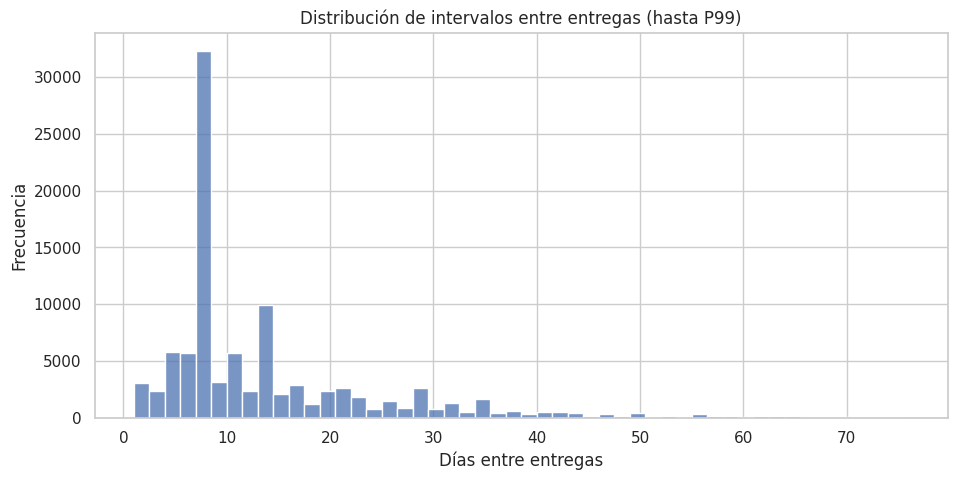

In [ ]:

eventos["intervalo_anterior"] = (
    eventos.groupby("rut")["fecha"].diff().dt.days
)

intervalos = eventos["intervalo_anterior"].dropna()

display(
    intervalos.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

plt.figure(figsize=(11,5))
sns.histplot(
    intervalos[intervalos <= intervalos.quantile(0.99)],
    bins=50
)
plt.title("Distribución de intervalos entre entregas (hasta P99)")
plt.xlabel("Días entre entregas")
plt.ylabel("Frecuencia")
plt.show()


## 5. Construcción del dataset supervisado

In [ ]:

RANGE_LABELS = [
    "Muy pronto",
    "Semanal",
    "Quincenal",
    "Mensual",
    "Largo plazo"
]

RANGE_BINS = [0, 5, 8, 15, 30, np.inf]

RANGE_ORDER = {
    "Muy pronto": 0,
    "Semanal": 1,
    "Quincenal": 2,
    "Mensual": 3,
    "Largo plazo": 4
}

def trend(values):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return 0.0
    return float(np.polyfit(np.arange(len(values)), values, 1)[0])

def build_supervised_events(events, window=5):
    rows = []

    for patient_source_id, g in events.groupby("rut"):
        g = g.sort_values("fecha").reset_index(drop=True)
        dates = g["fecha"].tolist()
        internal_ids = g["id"].tolist()

        if len(dates) < window + 2:
            continue

        intervals = np.diff(
            np.array(dates, dtype="datetime64[D]")
        ).astype("timedelta64[D]").astype(int)

        for i in range(window, len(intervals)):
            hist = intervals[:i]

            if len(hist) < window or np.any(hist <= 0):
                continue

            recent = hist[-window:]
            target_days = int(intervals[i])

            if target_days <= 0:
                continue

            current_event_date = pd.Timestamp(dates[i])
            target_event_date = pd.Timestamp(dates[i + 1])

            median_hist = float(np.median(hist))
            mean_hist = float(np.mean(hist))
            std_hist = float(np.std(hist))

            rows.append({
                "patient_source_id": patient_source_id,
                "id": internal_ids[i],
                "current_date": current_event_date,
                "target_date": target_event_date,

                "lag_1": float(recent[-1]),
                "lag_2": float(recent[-2]),
                "lag_3": float(recent[-3]),
                "lag_4": float(recent[-4]),
                "lag_5": float(recent[-5]),

                "hist_median": median_hist,
                "hist_mean": mean_hist,
                "hist_std": std_hist,
                "hist_min": float(np.min(hist)),
                "hist_max": float(np.max(hist)),
                "hist_q25": float(np.percentile(hist, 25)),
                "hist_q75": float(np.percentile(hist, 75)),
                "hist_cv": std_hist / (mean_hist + 1e-6),

                "recent_trend": trend(recent),
                "last_vs_median": float(recent[-1] / (median_hist + 1e-6)),
                "n_hist_intervals": len(hist),

                "current_month": current_event_date.month,
                "current_dow": current_event_date.dayofweek,
                "current_day": current_event_date.day,

                "target_days": target_days
            })

    result = pd.DataFrame(rows)

    result["target_range"] = pd.cut(
        result["target_days"],
        bins=RANGE_BINS,
        labels=RANGE_LABELS,
        include_lowest=True
    ).astype(str)

    return result

panel = build_supervised_events(eventos, window=5)

print(f"Instancias: {len(panel):,}")
print(f"Pacientes: {panel['patient_source_id'].nunique():,}")
print(f"Targets: {panel['target_date'].min().date()} -> {panel['target_date'].max().date()}")

display(panel.head(10))


Instancias: 76,629
Pacientes: 4,377
Targets: 2025-01-15 -> 2025-11-29


,patient_source_id,id,current_date,target_date,lag_1,lag_2,lag_3,lag_4,lag_5,hist_median,hist_mean,hist_std,hist_min,hist_max,hist_q25,hist_q75,hist_cv,recent_trend,last_vs_median,n_hist_intervals,current_month,current_dow,current_day,target_days,target_range
0,100124793,<NA>,2025-04-08,2025-04-29,21.0,14.0,14.0,21.0,21.0,21.0,18.200000,3.429286,14.0,21.0,14.00,21.0,0.188422,-0.7,1.000000,5,4,1,8,21,Mensual
1,100124793,<NA>,2025-04-29,2025-05-20,21.0,21.0,14.0,14.0,21.0,21.0,18.666667,3.299832,14.0,21.0,15.75,21.0,0.176777,0.7,1.000000,6,4,1,29,21,Mensual
2,100124793,<NA>,2025-05-20,2025-06-17,21.0,21.0,21.0,14.0,14.0,21.0,19.000000,3.162278,14.0,21.0,17.50,21.0,0.166436,2.1,1.000000,7,5,1,20,28,Mensual
3,100124793,<NA>,2025-06-17,2025-07-08,28.0,21.0,21.0,21.0,14.0,21.0,20.125000,4.196353,14.0,28.0,19.25,21.0,0.208514,2.8,1.333333,8,6,1,17,21,Mensual
4,100124793,<NA>,2025-07-08,2025-07-22,21.0,28.0,21.0,21.0,21.0,21.0,20.222222,3.965904,14.0,28.0,21.00,21.0,0.196116,0.7,1.000000,9,7,1,8,14,Quincenal
5,100124793,<NA>,2025-07-22,2025-08-12,14.0,21.0,28.0,21.0,21.0,21.0,19.600000,4.200000,14.0,28.0,15.75,21.0,0.214286,-1.4,0.666667,10,7,1,22,21,Mensual
6,100124793,<NA>,2025-08-12,2025-08-19,21.0,14.0,21.0,28.0,21.0,21.0,19.727273,4.024717,14.0,28.0,17.50,21.0,0.204018,-1.4,1.000000,11,8,1,12,7,Semanal
7,100124793,<NA>,2025-08-19,2025-09-02,7.0,21.0,14.0,21.0,28.0,21.0,18.666667,5.217492,7.0,28.0,14.00,21.0,0.279508,-4.2,0.333333,12,8,1,19,14,Quincenal
8,100124793,<NA>,2025-09-02,2025-09-23,14.0,7.0,21.0,14.0,21.0,21.0,18.307692,5.164742,7.0,28.0,14.00,21.0,0.282108,-2.1,0.666667,13,9,1,2,21,Mensual
9,100124793,<NA>,2025-09-23,2025-09-30,21.0,14.0,7.0,21.0,14.0,21.0,18.500000,5.024938,7.0,28.0,14.00,21.0,0.271618,0.7,1.000000,14,9,1,23,7,Semanal


,N
target_range,
Muy pronto,9735
Semanal,33339
Quincenal,18186
Mensual,11112
Largo plazo,4257


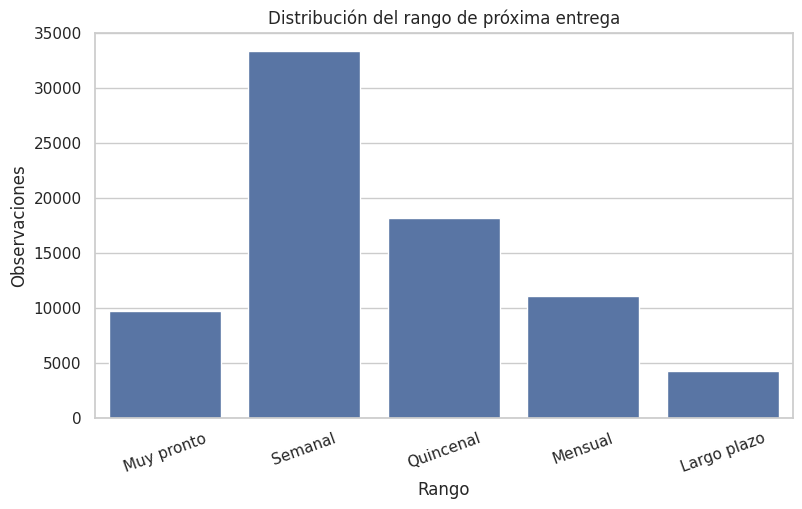

In [ ]:

class_distribution = (
    panel["target_range"]
    .value_counts()
    .reindex(RANGE_LABELS)
)

display(class_distribution.to_frame("N"))

plt.figure(figsize=(9,5))
sns.barplot(x=class_distribution.index, y=class_distribution.values)
plt.title("Distribución del rango de próxima entrega")
plt.xlabel("Rango")
plt.ylabel("Observaciones")
plt.xticks(rotation=20)
plt.show()


## 6. Features

In [ ]:

FEATURES = [
    "lag_1", "lag_2", "lag_3", "lag_4", "lag_5",
    "hist_median", "hist_mean", "hist_std",
    "hist_min", "hist_max",
    "hist_q25", "hist_q75", "hist_cv",
    "recent_trend", "last_vs_median",
    "n_hist_intervals",
    "current_month", "current_dow", "current_day"
]

print(f"Features: {len(FEATURES)}")
print(FEATURES)


Features: 19
['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'hist_median', 'hist_mean', 'hist_std', 'hist_min', 'hist_max', 'hist_q25', 'hist_q75', 'hist_cv', 'recent_trend', 'last_vs_median', 'n_hist_intervals', 'current_month', 'current_dow', 'current_day']


## 7. Métricas y baseline

In [ ]:

def days_to_range(days):
    if days <= 5:
        return "Muy pronto"
    elif days <= 8:
        return "Semanal"
    elif days <= 15:
        return "Quincenal"
    elif days <= 30:
        return "Mensual"
    return "Largo plazo"

def within_one_range(y_true, y_pred):
    true_idx = np.array([RANGE_ORDER[x] for x in y_true])
    pred_idx = np.array([RANGE_ORDER[x] for x in y_pred])
    return np.mean(np.abs(true_idx - pred_idx) <= 1)

def evaluate_classifier(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1_macro": f1_score(y_true, y_pred, average="macro"),
        "Within_1_range": within_one_range(y_true, y_pred)
    }


## 8. Comparación temporal de clasificadores

In [ ]:

CLASSIFIERS = {
    "RandomForest": RandomForestClassifier(
        n_estimators=350,
        max_depth=14,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "GradientBoosting": GradientBoostingClassifier(
        n_estimators=250,
        learning_rate=0.04,
        max_depth=3,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    )
}

BACKTEST_MONTHS = [7, 8, 9]
backtest_rows = []

for model_name, model in CLASSIFIERS.items():
    for month in BACKTEST_MONTHS:
        month_start = pd.Timestamp(2025, month, 1)
        month_end = month_start + pd.offsets.MonthEnd(1)

        train = panel[panel["target_date"] < month_start].copy()
        valid = panel[
            (panel["target_date"] >= month_start) &
            (panel["target_date"] <= month_end)
        ].copy()

        if len(train) == 0 or len(valid) == 0:
            continue

        if model_name == "GradientBoosting":
            weights = compute_sample_weight(
                class_weight="balanced",
                y=train["target_range"]
            )
            model.fit(
                train[FEATURES],
                train["target_range"],
                sample_weight=weights
            )
        else:
            model.fit(train[FEATURES], train["target_range"])

        pred = model.predict(valid[FEATURES])
        metrics = evaluate_classifier(valid["target_range"], pred)

        baseline_pred = valid["hist_median"].apply(days_to_range)
        baseline_metrics = evaluate_classifier(
            valid["target_range"],
            baseline_pred
        )

        backtest_rows.append({
            "Modelo": model_name,
            "Mes_validacion": month,
            "N": len(valid),
            **metrics,
            "Baseline_accuracy": baseline_metrics["Accuracy"]
        })

backtest = pd.DataFrame(backtest_rows)
display(backtest.round(4))


,Modelo,Mes_validacion,N,Accuracy,F1_macro,Within_1_range,Baseline_accuracy
0,RandomForest,7,8987,0.6413,0.5161,0.9017,0.6394
1,RandomForest,8,8935,0.6361,0.5426,0.9185,0.6241
2,RandomForest,9,9462,0.6257,0.5551,0.8833,0.6261
3,GradientBoosting,7,8987,0.5883,0.4893,0.8363,0.6394
4,GradientBoosting,8,8935,0.5627,0.4945,0.8467,0.6241
5,GradientBoosting,9,9462,0.5652,0.5139,0.8265,0.6261


In [ ]:

summary_backtest = (
    backtest.groupby("Modelo")
    .agg(
        Accuracy=("Accuracy", "mean"),
        F1_macro=("F1_macro", "mean"),
        Within_1_range=("Within_1_range", "mean"),
        Baseline_accuracy=("Baseline_accuracy", "mean")
    )
    .sort_values(["F1_macro", "Accuracy"], ascending=False)
)

display(summary_backtest.round(4))

BEST_CLASSIFIER_NAME = summary_backtest.index[0]
print(f"Clasificador seleccionado: {BEST_CLASSIFIER_NAME}")


,Accuracy,F1_macro,Within_1_range,Baseline_accuracy
Modelo,,,,
RandomForest,0.6344,0.5380,0.9012,0.6298
GradientBoosting,0.5721,0.4992,0.8365,0.6298


Clasificador seleccionado: RandomForest


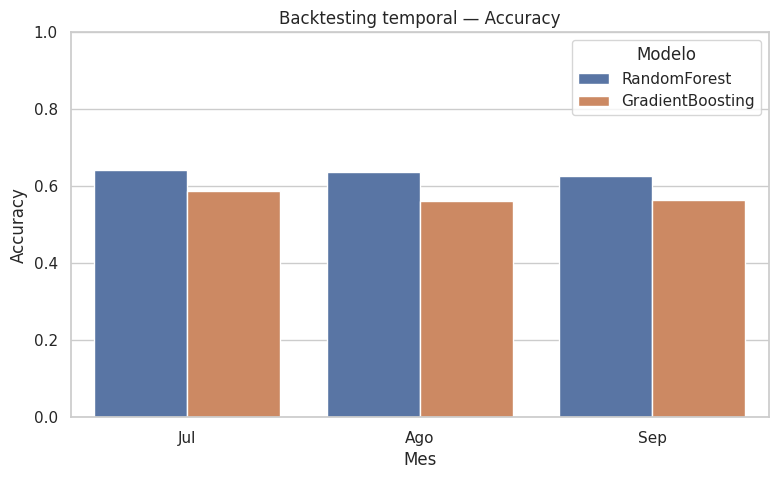

In [ ]:

plot_bt = backtest.copy()
plot_bt["Mes"] = plot_bt["Mes_validacion"].map({7:"Jul",8:"Ago",9:"Sep"})

plt.figure(figsize=(9,5))
sns.barplot(data=plot_bt, x="Mes", y="Accuracy", hue="Modelo")
plt.title("Backtesting temporal — Accuracy")
plt.ylim(0,1)
plt.show()


## 9. Test final: octubre–noviembre

In [ ]:

TEST_START = pd.Timestamp("2025-10-01")
TEST_END = pd.Timestamp("2025-11-30")

train_final = panel[panel["target_date"] < TEST_START].copy()
test_final = panel[
    (panel["target_date"] >= TEST_START) &
    (panel["target_date"] <= TEST_END)
].copy()

best_classifier = CLASSIFIERS[BEST_CLASSIFIER_NAME]

if BEST_CLASSIFIER_NAME == "GradientBoosting":
    weights = compute_sample_weight(
        class_weight="balanced",
        y=train_final["target_range"]
    )
    best_classifier.fit(
        train_final[FEATURES],
        train_final["target_range"],
        sample_weight=weights
    )
else:
    best_classifier.fit(
        train_final[FEATURES],
        train_final["target_range"]
    )

pred_class = best_classifier.predict(test_final[FEATURES])

class_metrics = evaluate_classifier(
    test_final["target_range"],
    pred_class
)

baseline_class = test_final["hist_median"].apply(days_to_range)
baseline_metrics = evaluate_classifier(
    test_final["target_range"],
    baseline_class
)

print(f"Modelo: {BEST_CLASSIFIER_NAME}")
print(f"Train: {len(train_final):,}")
print(f"Test: {len(test_final):,}")

print("\nMODELO")
for k,v in class_metrics.items():
    print(f"{k:18s}: {v:.4f} ({v*100:.2f}%)")

print("\nBASELINE")
for k,v in baseline_metrics.items():
    print(f"{k:18s}: {v:.4f} ({v*100:.2f}%)")


Modelo: RandomForest
Train: 57,813
Test: 18,816

MODELO
Accuracy          : 0.6240 (62.40%)
F1_macro          : 0.5457 (54.57%)
Within_1_range    : 0.9088 (90.88%)

BASELINE
Accuracy          : 0.6161 (61.61%)
F1_macro          : 0.5476 (54.76%)
Within_1_range    : 0.9192 (91.92%)


In [ ]:

print(classification_report(
    test_final["target_range"],
    pred_class,
    labels=RANGE_LABELS,
    zero_division=0
))


              precision    recall  f1-score   support

  Muy pronto       0.51      0.60      0.55      2447
     Semanal       0.87      0.70      0.78      7348
   Quincenal       0.51      0.70      0.59      4101
     Mensual       0.48      0.64      0.55      3128
 Largo plazo       0.95      0.15      0.26      1792

    accuracy                           0.62     18816
   macro avg       0.66      0.56      0.55     18816
weighted avg       0.69      0.62      0.62     18816



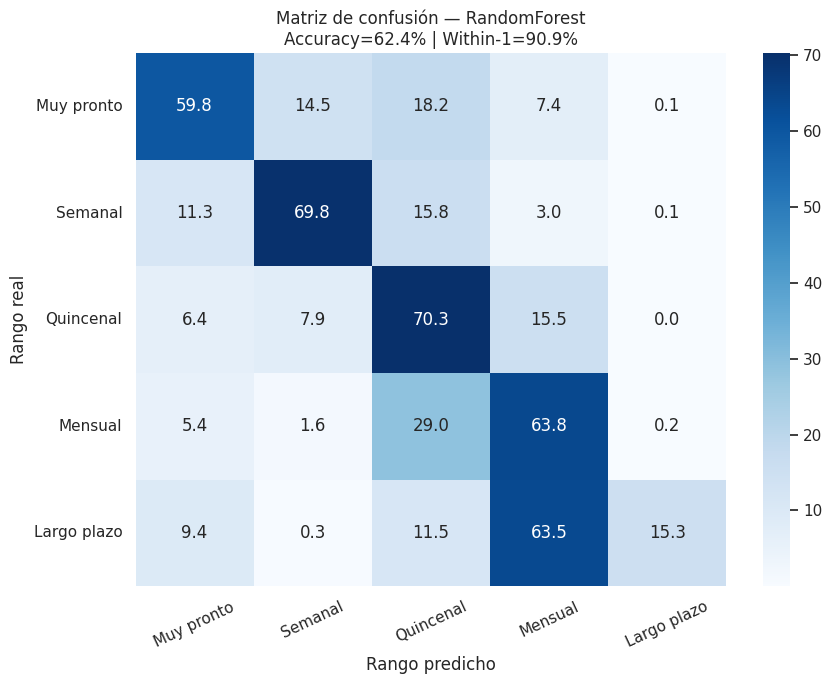

In [ ]:

cm = confusion_matrix(
    test_final["target_range"],
    pred_class,
    labels=RANGE_LABELS
)

cm_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100

plt.figure(figsize=(9,7))
sns.heatmap(
    cm_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=RANGE_LABELS,
    yticklabels=RANGE_LABELS
)

plt.title(
    f"Matriz de confusión — {BEST_CLASSIFIER_NAME}\n"
    f"Accuracy={class_metrics['Accuracy']*100:.1f}% | "
    f"Within-1={class_metrics['Within_1_range']*100:.1f}%"
)
plt.xlabel("Rango predicho")
plt.ylabel("Rango real")
plt.xticks(rotation=25)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 10. Regresión secundaria de días

In [ ]:

REGRESSORS = {
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=350,
        max_depth=14,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "GradientBoostingRegressor": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=5,
        loss="huber",
        random_state=RANDOM_STATE
    )
}

reg_rows = []

for model_name, model in REGRESSORS.items():
    model.fit(train_final[FEATURES], train_final["target_days"])

    pred_days = np.maximum(
        1,
        model.predict(test_final[FEATURES])
    )

    reg_rows.append({
        "Modelo": model_name,
        "MAE_dias": mean_absolute_error(
            test_final["target_days"], pred_days
        ),
        "RMSE_dias": np.sqrt(
            mean_squared_error(
                test_final["target_days"], pred_days
            )
        ),
        "R2": r2_score(
            test_final["target_days"], pred_days
        ),
        "Dentro_3_dias": np.mean(
            np.abs(test_final["target_days"].values - pred_days) <= 3
        ),
        "Dentro_7_dias": np.mean(
            np.abs(test_final["target_days"].values - pred_days) <= 7
        )
    })

reg_results = pd.DataFrame(reg_rows).sort_values("MAE_dias")
display(reg_results.round(4))

BEST_REGRESSOR_NAME = reg_results.iloc[0]["Modelo"]
print(f"Regresor seleccionado: {BEST_REGRESSOR_NAME}")


,Modelo,MAE_dias,RMSE_dias,R2,Dentro_3_dias,Dentro_7_dias
0,RandomForestRegressor,5.9334,11.8682,0.1925,0.5974,0.7636
1,GradientBoostingRegressor,6.1985,12.0559,0.1668,0.5724,0.7537


Regresor seleccionado: RandomForestRegressor


In [ ]:

best_regressor = REGRESSORS[BEST_REGRESSOR_NAME]
best_regressor.fit(train_final[FEATURES], train_final["target_days"])

pred_days_test = np.maximum(
    1,
    best_regressor.predict(test_final[FEATURES])
)

baseline_days = test_final["hist_median"].values

print(
    "MAE modelo:",
    round(mean_absolute_error(test_final["target_days"], pred_days_test), 3),
    "días"
)

print(
    "MAE baseline:",
    round(mean_absolute_error(test_final["target_days"], baseline_days), 3),
    "días"
)


MAE modelo: 5.933 días
MAE baseline: 4.801 días


## 11. Importancia de variables

,importancia
hist_mean,0.122514
hist_q75,0.110367
lag_1,0.110150
hist_median,0.095398
hist_max,0.070920
hist_q25,0.068183
hist_std,0.050787
lag_2,0.050575
last_vs_median,0.044139
lag_3,0.044012


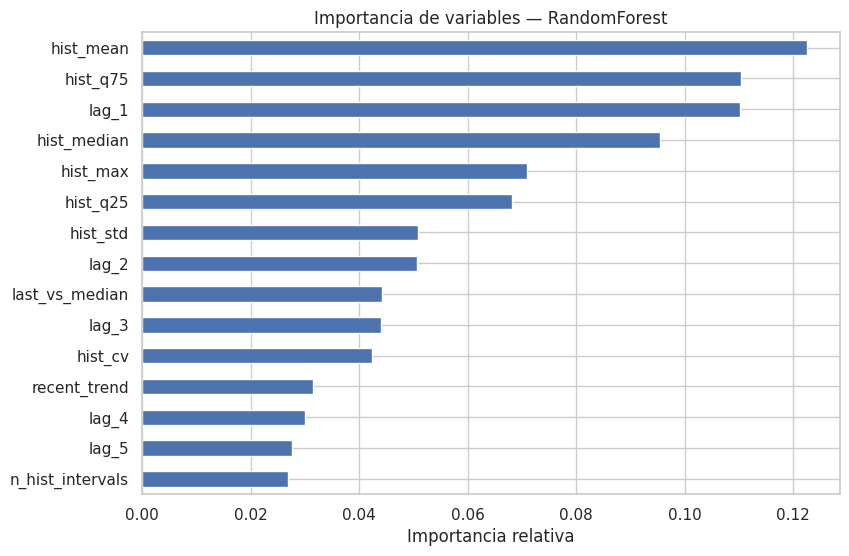

In [ ]:

if hasattr(best_classifier, "feature_importances_"):
    importance = pd.Series(
        best_classifier.feature_importances_,
        index=FEATURES
    ).sort_values(ascending=False)

    display(importance.head(15).to_frame("importancia"))

    plt.figure(figsize=(9,6))
    importance.head(15).sort_values().plot(kind="barh")
    plt.title(f"Importancia de variables — {BEST_CLASSIFIER_NAME}")
    plt.xlabel("Importancia relativa")
    plt.show()


## 12. Entrenamiento definitivo

In [ ]:

production_classifier = CLASSIFIERS[BEST_CLASSIFIER_NAME]
production_regressor = REGRESSORS[BEST_REGRESSOR_NAME]

if BEST_CLASSIFIER_NAME == "GradientBoosting":
    weights = compute_sample_weight(
        class_weight="balanced",
        y=panel["target_range"]
    )
    production_classifier.fit(
        panel[FEATURES],
        panel["target_range"],
        sample_weight=weights
    )
else:
    production_classifier.fit(
        panel[FEATURES],
        panel["target_range"]
    )

production_regressor.fit(
    panel[FEATURES],
    panel["target_days"]
)

print("Modelos de producción entrenados.")


Modelos de producción entrenados.


## 13. Construir predicción actual por paciente

In [ ]:

def build_current_patient_features(events, window=5):
    rows = []

    for patient_source_id, g in events.groupby("rut"):
        g = g.sort_values("fecha").reset_index(drop=True)
        dates = g["fecha"].tolist()

        if len(dates) < window + 1:
            continue

        intervals = np.diff(
            np.array(dates, dtype="datetime64[D]")
        ).astype("timedelta64[D]").astype(int)

        intervals = intervals[intervals > 0]

        if len(intervals) < window:
            continue

        hist = intervals
        recent = hist[-window:]
        current_date = pd.Timestamp(dates[-1])

        median_hist = float(np.median(hist))
        mean_hist = float(np.mean(hist))
        std_hist = float(np.std(hist))

        rows.append({
            "patient_source_id": patient_source_id,
            "id": first_valid(g["id"]),
            "last_delivery_date": current_date,

            "lag_1": float(recent[-1]),
            "lag_2": float(recent[-2]),
            "lag_3": float(recent[-3]),
            "lag_4": float(recent[-4]),
            "lag_5": float(recent[-5]),

            "hist_median": median_hist,
            "hist_mean": mean_hist,
            "hist_std": std_hist,
            "hist_min": float(np.min(hist)),
            "hist_max": float(np.max(hist)),
            "hist_q25": float(np.percentile(hist,25)),
            "hist_q75": float(np.percentile(hist,75)),
            "hist_cv": std_hist/(mean_hist+1e-6),

            "recent_trend": trend(recent),
            "last_vs_median": float(recent[-1]/(median_hist+1e-6)),
            "n_hist_intervals": len(hist),

            "current_month": current_date.month,
            "current_dow": current_date.dayofweek,
            "current_day": current_date.day
        })

    return pd.DataFrame(rows)

current_features = build_current_patient_features(eventos, window=5)

print(
    "Pacientes con historial suficiente:",
    f"{len(current_features):,}"
)

display(current_features.head())


Pacientes con historial suficiente: 4,525


,patient_source_id,id,last_delivery_date,lag_1,lag_2,lag_3,lag_4,lag_5,hist_median,hist_mean,hist_std,hist_min,hist_max,hist_q25,hist_q75,hist_cv,recent_trend,last_vs_median,n_hist_intervals,current_month,current_dow,current_day
0,100124793,<NA>,2025-11-25,7.0,7.0,7.0,7.0,7.0,14.0,14.000000,7.021705,1.0,28.0,7.00,21.0,0.501550,-6.397204e-16,0.500000,23,11,1,25
1,100132869,2486,2025-11-24,14.0,7.0,7.0,6.0,9.0,7.0,9.757576,4.163553,6.0,22.0,7.00,13.0,0.426699,1.100000e+00,2.000000,33,11,0,24
2,100181541,<NA>,2025-11-25,5.0,9.0,6.0,6.0,7.0,7.0,8.729730,3.908747,5.0,22.0,7.00,9.0,0.447751,-1.000000e-01,0.714286,37,11,1,25
3,1001817,<NA>,2025-11-26,15.0,12.0,16.0,13.0,14.0,14.0,14.636364,2.079018,12.0,22.0,13.00,15.0,0.142045,1.000000e-01,1.071428,22,11,2,26
4,10019192K,2911,2025-11-25,36.0,27.0,28.0,29.0,33.0,29.0,30.200000,3.370460,26.0,36.0,28.25,32.0,0.111605,4.000000e-01,1.241379,10,11,1,25


In [ ]:

predicted_range = production_classifier.predict(
    current_features[FEATURES]
)

range_probabilities = production_classifier.predict_proba(
    current_features[FEATURES]
)

confidence = range_probabilities.max(axis=1)

predicted_days_raw = np.maximum(
    1,
    production_regressor.predict(current_features[FEATURES])
)

predicted_days = np.rint(predicted_days_raw).astype(int)

predicciones = current_features[
    ["id", "patient_source_id", "last_delivery_date"]
].copy()

predicciones["rango_estimado"] = predicted_range
predicciones["confianza_rango"] = confidence
predicciones["dias_estimados"] = predicted_days

predicciones["fecha_estimada"] = (
    predicciones["last_delivery_date"] +
    pd.to_timedelta(predicciones["dias_estimados"], unit="D")
)

display(predicciones.head(20))


,id,patient_source_id,last_delivery_date,rango_estimado,confianza_rango,dias_estimados,fecha_estimada
0,<NA>,100124793,2025-11-25,Semanal,0.447204,7,2025-12-02
1,2486,100132869,2025-11-24,Quincenal,0.435494,9,2025-12-03
2,<NA>,100181541,2025-11-25,Semanal,0.422695,8,2025-12-03
3,<NA>,1001817,2025-11-26,Quincenal,0.782564,14,2025-12-10
4,2911,10019192K,2025-11-25,Mensual,0.409032,6,2025-12-01
5,<NA>,100232413,2025-11-18,Mensual,0.647219,15,2025-12-03
6,2487,100258102,2025-11-16,Quincenal,0.340148,10,2025-11-26
7,<NA>,100310848,2025-10-28,Largo plazo,0.503430,23,2025-11-20
8,<NA>,100387395,2025-11-25,Semanal,0.740582,7,2025-12-02
9,<NA>,100545411,2025-11-20,Quincenal,0.935068,14,2025-12-04


## 14. Función para llamar al componente predictivo

In [ ]:

def predecir_proxima_entrega(identifier):
    match = predicciones[
        predicciones["id"].astype(str) == str(identifier)
    ]

    if match.empty:
        match = predicciones[
            predicciones["patient_source_id"].astype(str) == str(identifier)
        ]

    if match.empty:
        raise ValueError(
            "Paciente no encontrado o historial insuficiente."
        )

    row = match.iloc[0]

    return {
        "id": None if pd.isna(row["id"]) else row["id"],
        "ultima_entrega": row["last_delivery_date"].strftime("%Y-%m-%d"),
        "rango_estimado": row["rango_estimado"],
        "confianza_rango": round(float(row["confianza_rango"]), 3),
        "dias_estimados": int(row["dias_estimados"]),
        "fecha_estimada": row["fecha_estimada"].strftime("%Y-%m-%d")
    }

example_identifier = (
    predicciones["id"].dropna().iloc[0]
    if predicciones["id"].notna().any()
    else predicciones["patient_source_id"].iloc[0]
)

predecir_proxima_entrega(example_identifier)


{'id': '2486',
 'ultima_entrega': '2025-11-24',
 'rango_estimado': 'Quincenal',
 'confianza_rango': 0.435,
 'dias_estimados': 9,
 'fecha_estimada': '2025-12-03'}

## 15. Guardar artefactos

In [ ]:

BUNDLE_FILE = "modelo_proxima_entrega.joblib"
PRED_FILE = "predicciones_proxima_entrega.csv"
TEST_FILE = "evaluacion_proxima_entrega_oct_nov.csv"
META_FILE = "modelo_proxima_entrega_metadata.json"

bundle = {
    "classifier": production_classifier,
    "regressor": production_regressor,
    "features": FEATURES,
    "range_labels": RANGE_LABELS,
    "range_bins": RANGE_BINS
}

joblib.dump(bundle, BUNDLE_FILE)

predicciones.drop(
    columns=["patient_source_id"],
    errors="ignore"
).to_csv(PRED_FILE, index=False)

test_export = test_final[
    ["id", "current_date", "target_date", "target_days", "target_range"]
].copy()

test_export["rango_predicho"] = pred_class
test_export["dias_predichos"] = np.rint(pred_days_test).astype(int)

test_export.to_csv(TEST_FILE, index=False)

metadata = {
    "objetivo": "Estimar cuándo ocurrirá la próxima entrega",
    "clasificador": BEST_CLASSIFIER_NAME,
    "regresor": BEST_REGRESSOR_NAME,
    "features": FEATURES,
    "id_usado_como_predictor": False,
    "test_periodo": "octubre-noviembre 2025",
    "test_clasificacion": {
        "accuracy": float(class_metrics["Accuracy"]),
        "f1_macro": float(class_metrics["F1_macro"]),
        "within_1_range": float(class_metrics["Within_1_range"])
    },
    "test_regresion": {
        "mae_dias": float(
            mean_absolute_error(
                test_final["target_days"],
                pred_days_test
            )
        ),
        "rmse_dias": float(
            np.sqrt(
                mean_squared_error(
                    test_final["target_days"],
                    pred_days_test
                )
            )
        ),
        "r2": float(
            r2_score(
                test_final["target_days"],
                pred_days_test
            )
        )
    }
}

with open(META_FILE, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Archivos generados:")
print("-", BUNDLE_FILE)
print("-", PRED_FILE)
print("-", TEST_FILE)
print("-", META_FILE)


Archivos generados:
- modelo_proxima_entrega.joblib
- predicciones_proxima_entrega.csv
- evaluacion_proxima_entrega_oct_nov.csv
- modelo_proxima_entrega_metadata.json


## 16. Descargar modelo

In [ ]:

files.download("modelo_proxima_entrega.joblib")

# files.download("predicciones_proxima_entrega.csv")
# files.download("evaluacion_proxima_entrega_oct_nov.csv")
# files.download("modelo_proxima_entrega_metadata.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# Integración

La función principal es:

```python
predecir_proxima_entrega(id_paciente)
```

Ejemplo conceptual:

```python
{
    "id": 2486,
    "ultima_entrega": "2025-11-24",
    "rango_estimado": "Semanal",
    "confianza_rango": 0.81,
    "dias_estimados": 7,
    "fecha_estimada": "2025-12-01"
}
```

Para la aplicación:
- `rango_estimado` es la salida operacional principal.
- `fecha_estimada` es una estimación complementaria.
- `confianza_rango` permite identificar predicciones que podrían requerir revisión.
